# Klasifikasi Penyakit Daun Tanaman (Versi 27 Kelas)
## Machine Learning Competition — Informatics Festival (I-Fest) 6.0
### HIMIF Universitas Multi Data Palembang

---

## Identitas Kelompok

| Atribut        | Detail                              |
|----------------|-------------------------------------|
| **Nama Tim**   | Belum Kepikiran                     |
| **Kompetisi**  | Machine Learning                    |
| **Ketua**      | Elvionita Sahara                    |
| **Anggota 1**  | M. Ma'ruf Qomaruddin Kafi           |

---

## Deskripsi Proyek

Notebook ini berisi solusi untuk klasifikasi **penyakit daun** pada empat jenis tanaman:
- **Kentang**
- **Lemon**
- **Teh**
- **Tomat**

Model dibangun menggunakan **Convolutional Neural Network (CNN) dari nol** (tanpa pretrained model / transfer learning), sesuai ketentuan kompetisi. Total terdapat **27 kelas** penyakit dan kondisi daun yang diklasifikasikan.

---

## Struktur Folder Google Drive
sebelum melakukan runing cell code dibawah, usahakan untuk membuat struktur folder seperti berikut
```
MACHINE LEARNING_IFEST6.0_belum kepikiran/
├── dataset/
│   ├── raw/
│   │   └── archive_folder.zip                             -> Dataset mentah (archive_folder.zip) yang belum di-split
│   └── split/                                             -> Hasil split train (80%), val (10%), test (10%) yang merupakan hasil generate cell 5 dan hasil output dari cell 10 dan disimpan dengan nama file split_dataset_backup
├── notebooks/
│   └── MACHINE LEARNING_IFEST6.0_belum kepikiran_27 Kelas.ipynb    -> File notebook utama pengerjaan
└── models/
    └── best_model.h5                                      -> Model terbaik (disimpan otomatis via ModelCheckpoint)
```

adapun untuk isi file archive_folder.zip adalah sebagai berikut:
```
archive_folder
├── Kentang
│  ├── Early_blight
│   ├── healthy
│   └── Late_blight
├── Lemon
│   ├── Anthracnose
│   ├── Bacterial Blight
│   ├── Citrus Canker
│   ├── Curl Virus
│   ├── Deficiency Leaf
│   ├── Dry Leaf
│   ├── Healthy Leaf
│   ├── Sooty Mould
│   └── Spider Mites
├── Teh
│   ├── algal leaf
│   ├── bird eye spot
│   ├── brown blight
│   ├── gray blight
│   └── healthy
└── Tomat
    ├── Bacterial_spot
    ├── Early_blight
    ├── healthy
    ├── Late_blight
    ├── Leaf_Mold
    ├── Septoria_leaf_spot
    ├── Spider_mites Two-spotted_spider_mite
    ├── Target_Spot
    ├── Tomato_mosaic_virus
    └── Tomato_Yellow_Leaf_Curl_Virus
```
dimana tiap folder berisi file gambar daun dengan kategori masing-masing.

---

## Cara Menjalankan Notebook

Ikuti langkah-langkah berikut **secara berurutan**:

| Cell | Fungsi |
|------|--------|
| **Cell 1** | Dokumentasi (ini) dimohon untuk membaca dahulu sebelum memulai |
| **Cell 2** | Mount Google Drive |
| **Cell 3** | Ekstrak dataset dari `archive_folder.zip` |
| **Cell 4** | Eksplorasi data (EDA) & visualisasi sebaran kelas |
| **Cell 5** | Split dataset -> train / val / test |
| **Cell 6** | Preprocessing & augmentasi data |
| **Cell 7** | Membangun arsitektur CNN |
| **Cell 8** | Training model |
| **Cell 9** | Evaluasi model (akurasi, confusion matrix, classification report) |
| **Cell 10** | *(Opsional)* Backup split dataset ke Google Drive |
| **Cell 11** | Menyimpan Model Final & Download |
| **Cell 12** | Hasil Analisis dan Kesimpulan

> **Penting:** Pastikan Google Drive sudah ter-mount sebelum menjalankan Cell 3 ke atas.
> Jalankan setiap cell **satu per satu** dan tunggu hingga selesai sebelum lanjut ke cell berikutnya.

---

## Pendekatan Teknis

- **Arsitektur:** Custom CNN 5 layer konvolusi (32 → 64 → 128 → 256 → 512  filter)
- **Optimizer:** Adam (lr=0.001) dengan Early Stopping (patience=5)
- **Augmentasi:** Rescale, Rotation, Shift, Shear, Zoom, Flip, Brightness, dan Channel Shift (hanya pada data train)
- **Input size:** 150×150 piksel, 3 channel (RGB)
- **Output:** 27 kelas (Softmax)
- **Framework:** TensorFlow / Keras

---

*Notebook ini merupakan karya orisinal tim **Belum Kepikiran** untuk kompetisi I-Fest 6.0.*

In [ ]:
# ============================================================
# CELL 2 — Mount Google Drive
# Google Colab tidak bisa mengakses file di Drive secara
# langsung tanpa proses mount terlebih dahulu.
# ============================================================

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive berhasil di-mount!")
print("Drive tersedia di: /content/drive/MyDrive/")

Mounted at /content/drive
Google Drive berhasil di-mount!
Drive tersedia di: /content/drive/MyDrive/


In [ ]:
# ============================================================
# CELL 3 — Ekstrak archive_folder.zip dari Google Drive
# Menggunakan try-except untuk memastikan file tersedia sebelum proses ekstrak dijalankan
# ============================================================

import os
import zipfile

# Path sumber file zip di Google Drive
ZIP_PATH = "/content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/dataset/raw/archive_folder.zip"

# Path tujuan ekstraksi di lokal Colab
EXTRACT_PATH = "/content/MACHINE LEARNING_IFEST6.0_belum kepikiran/dataset/raw"

# Buat folder tujuan jika belum ada
os.makedirs(EXTRACT_PATH, exist_ok=True)

try:
    # Cek apakah file zip tersedia di Drive
    if not os.path.exists(ZIP_PATH):
        raise FileNotFoundError(
            f"File tidak ditemukan di path berikut:\n {ZIP_PATH}\n"
            f"Pastikan file archive_folder.zip sudah ada di Google Drive dan Drive sudah ter-mount (Cell 2)."
        )

    print(f"File ditemukan: {ZIP_PATH}")
    print(f"Mengekstrak dataset ke: {EXTRACT_PATH} ...")

    # Ekstrak zip dengan flag -q (quiet) agar tidak print satu per satu
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_PATH)

    print("Ekstraksi berhasil!")
    print(f"Dataset tersedia di: {EXTRACT_PATH}")

except FileNotFoundError as e:
    print(str(e))

except zipfile.BadZipFile:
    print("Error: File zip rusak atau tidak valid. Coba upload ulang archive_folder.zip ke Drive.")

except Exception as e:
    print(f"Terjadi error tak terduga: {e}")

File ditemukan: /content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/dataset/raw/archive_folder.zip
Mengekstrak dataset ke: /content/MACHINE LEARNING_IFEST6.0_belum kepikiran/dataset/raw ...
Ekstraksi berhasil!
Dataset tersedia di: /content/MACHINE LEARNING_IFEST6.0_belum kepikiran/dataset/raw


EKSPLORASI DATA — SEBARAN KELAS PER TANAMAN

 Kentang:
----------------------------------------
 Early_blight                   :   500 gambar
 Late_blight                    :   500 gambar
 healthy                        :   152 gambar
 ────────────────────────────────────────
Subtotal Kentang                    :  1152 gambar

 Lemon:
----------------------------------------
 Anthracnose                    :   100 gambar
 Bacterial Blight               :   105 gambar
 Citrus Canker                  :   178 gambar
 Curl Virus                     :   115 gambar
 Deficiency Leaf                :   193 gambar
 Dry Leaf                       :   186 gambar
 Healthy Leaf                   :   210 gambar
 Sooty Mould                    :   153 gambar
 Spider Mites                   :   114 gambar
 ────────────────────────────────────────
Subtotal Lemon                      :  1354 gambar

 Teh:
----------------------------------------
 algal leaf                     :   113 gambar
 bird eye

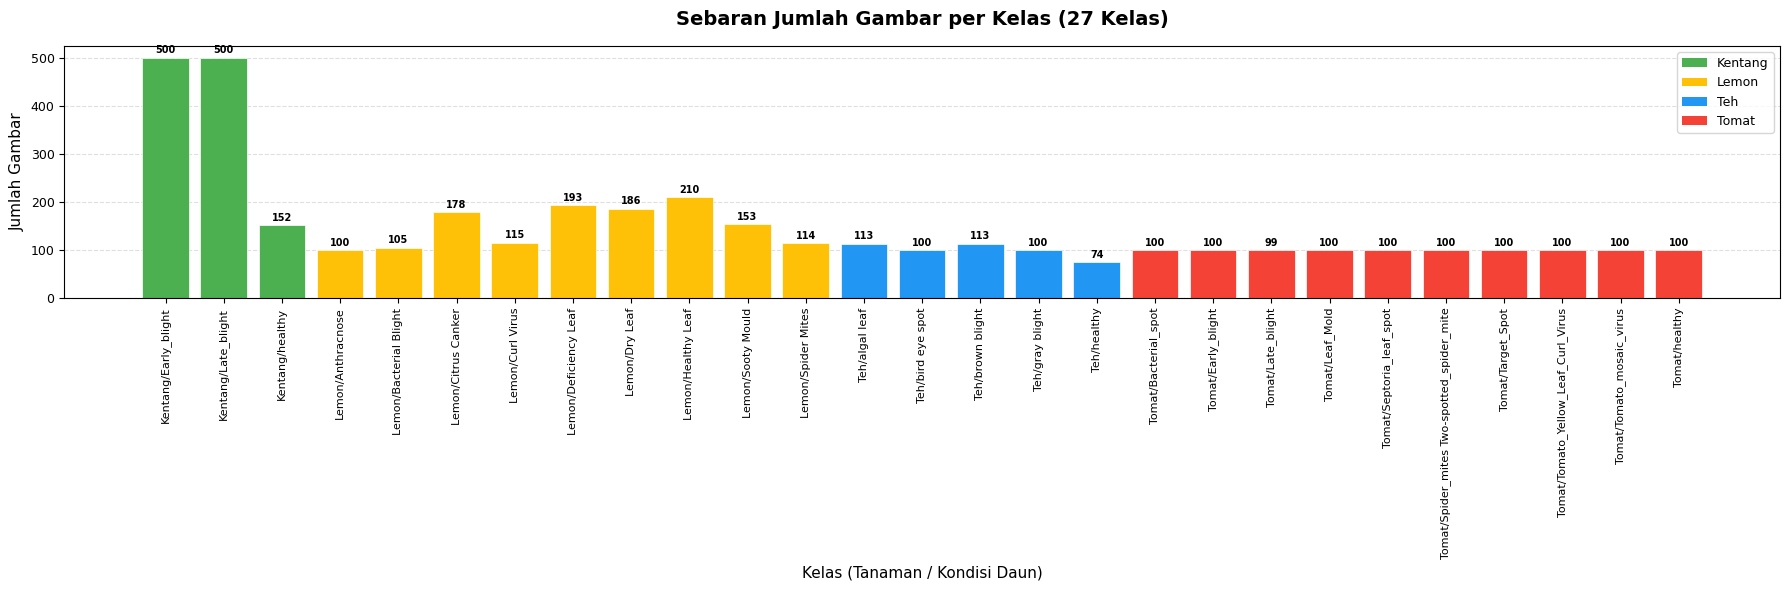


 Visualisasi sebaran kelas selesai.
Bar chart membantu mengidentifikasi class imbalance antar kelas.


In [ ]:
# ============================================================
# CELL 4 — Eksplorasi Data (EDA)
# Menampilkan jumlah total gambar, sebaran kelas per tanaman, dan visualisasi bar chart untuk analisis data imbalance
# ============================================================

import os
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Path dataset raw hasil ekstraksi
RAW_PATH = "/content/MACHINE LEARNING_IFEST6.0_belum kepikiran/dataset/raw"

# Tanaman yang dianalisis
PLANTS = ["Kentang", "Lemon", "Teh", "Tomat"]

# Dictionary untuk menyimpan jumlah gambar per kelas
class_counts = {}
plant_totals = {}

print("=" * 60)
print("EKSPLORASI DATA — SEBARAN KELAS PER TANAMAN")
print("=" * 60)

total_images = 0

for plant in PLANTS:
    plant_path = os.path.join(RAW_PATH, plant)

    # Cek apakah folder tanaman tersedia
    if not os.path.exists(plant_path):
        print(f"Folder tidak ditemukan: {plant_path}")
        continue

    diseases = sorted(os.listdir(plant_path))
    plant_total = 0

    print(f"\n {plant}:")
    print("-" * 40)

    for disease in diseases:
        disease_path = os.path.join(plant_path, disease)
        if not os.path.isdir(disease_path):
            continue

        # Hitung jumlah file gambar
        images = [
            f for f in os.listdir(disease_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
        ]
        count = len(images)
        label = f"{plant}/{disease}"
        class_counts[label] = count
        plant_total += count

        print(f" {disease:<30} : {count:>5} gambar")

    plant_totals[plant] = plant_total
    total_images += plant_total
    print(f" {'─'*40}")
    print(f"Subtotal {plant:<26} : {plant_total:>5} gambar")

print("\n" + "=" * 60)
print(f"TOTAL KESELURUHAN GAMBAR    : {total_images:>6} gambar")
print(f"TOTAL KELAS                 : {len(class_counts):>6} kelas")
print("=" * 60)

# ── Visualisasi Bar Chart Sebaran Kelas ──────────────────────
# Menampilkan distribusi gambar per kelas untuk memudahkan
# identifikasi kelas yang imbalanced (tidak seimbang).

labels = list(class_counts.keys())
counts = list(class_counts.values())

# Warna berbeda per tanaman
color_map = {
    "Kentang": "#4CAF50",
    "Lemon":   "#FFC107",
    "Teh":     "#2196F3",
    "Tomat":   "#F44336"
}

bar_colors = []
for label in labels:
    plant = label.split("/")[0]
    bar_colors.append(color_map.get(plant, "#9E9E9E"))

fig, ax = plt.subplots(figsize=(18, 6))

bars = ax.bar(labels, counts, color=bar_colors, edgecolor='white', linewidth=0.5)

# Tambahkan label jumlah di atas setiap bar
for bar, count in zip(bars, counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5,
        str(count),
        ha='center', va='bottom', fontsize=7, fontweight='bold'
    )

# Rotasi label sumbu X agar tidak tumpang tindih (27 kelas)
plt.xticks(rotation=90, fontsize=8)
plt.yticks(fontsize=9)

ax.set_title("Sebaran Jumlah Gambar per Kelas (27 Kelas)", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Kelas (Tanaman / Kondisi Daun)", fontsize=11)
ax.set_ylabel("Jumlah Gambar", fontsize=11)

# Legend tanaman
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=color_map[p], label=p) for p in PLANTS if p in color_map]
ax.legend(handles=legend_elements, loc='upper right', fontsize=9)

ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("sebaran_kelas.png", dpi=150, bbox_inches='tight')
plt.show()

print("\n Visualisasi sebaran kelas selesai.")
print("Bar chart membantu mengidentifikasi class imbalance antar kelas.")

In [ ]:
# ============================================================
# CELL 5 — Split Dataset (27 Kelas Penyakit)
# ============================================================

!pip install split-folders -q

import splitfolders
import os
import shutil

RAW_PATH   = "/content/MACHINE LEARNING_IFEST6.0_belum kepikiran/dataset/raw"
SPLIT_PATH = "/content/dataset/split"
PLANTS     = ["Kentang", "Lemon", "Teh", "Tomat"]
SEED       = 42

# 1. Bersihkan folder split lama jika ada agar tidak tumpang tindih
if os.path.exists(SPLIT_PATH):
    shutil.rmtree(SPLIT_PATH)
os.makedirs(SPLIT_PATH, exist_ok=True)

print("=" * 60)
print("MEMULAI PROSES SPLIT DATASET (TARGET: 27 KELAS)")
print("=" * 60)

for plant in PLANTS:
    plant_src = os.path.join(RAW_PATH, plant)
    if not os.path.exists(plant_src):
        continue

    # Folder temporary untuk proses split per tanaman
    plant_tmp = os.path.join(SPLIT_PATH, "_tmp")
    if os.path.exists(plant_tmp): shutil.rmtree(plant_tmp)

    print(f" Memproses penyakit pada tanaman: {plant}...")

    # Split data di dalam folder tanaman (isinya sub-folder penyakit)
    splitfolders.ratio(
        plant_src,
        output=plant_tmp,
        seed=SEED,
        ratio=(0.8, 0.1, 0.1),
        move=False
    )

    # Pindahkan hasil split ke folder utama dengan prefix nama tanaman
    # Agar folder 'healthy' milik Tomat beda dengan 'healthy' milik Kentang
    for subset in ["train", "val", "test"]:
        src_subset = os.path.join(plant_tmp, subset)
        dst_subset = os.path.join(SPLIT_PATH, subset)
        os.makedirs(dst_subset, exist_ok=True)

        for disease in os.listdir(src_subset):
            # Gabungkan nama tanaman dan penyakit (Contoh: Kentang_Early_blight)
            new_class_name = f"{plant}_{disease}"
            s = os.path.join(src_subset, disease)
            d = os.path.join(dst_subset, new_class_name)

            if os.path.isdir(s):
                shutil.copytree(s, d)

    # Hapus folder temporary
    shutil.rmtree(plant_tmp)

print("\n" + "=" * 60)
print("VERIFIKASI HASIL SPLIT (HARUS 27 KELAS)")
print("=" * 60)

for subset in ["train", "val", "test"]:
    subset_path = os.path.join(SPLIT_PATH, subset)
    num_classes = len([f for f in os.listdir(subset_path) if os.path.isdir(os.path.join(subset_path, f))]) if os.path.exists(subset_path) else 0
    total_imgs = sum([len(files) for r, d, files in os.walk(subset_path)])
    print(f" Subset {subset.upper():<5} : {num_classes:>2} kelas | {total_imgs:>5} gambar")

print("\nSplit dataset selesai! Struktur folder sekarang FLAT (27 folder di tiap subset).")

MEMULAI PROSES SPLIT DATASET (TARGET: 27 KELAS)
 Memproses penyakit pada tanaman: Kentang...


Copying files: 1152 files [00:00, 1292.48 files/s]


 Memproses penyakit pada tanaman: Lemon...


Copying files: 1354 files [00:05, 253.94 files/s]


 Memproses penyakit pada tanaman: Teh...


Copying files: 500 files [00:03, 144.76 files/s]


 Memproses penyakit pada tanaman: Tomat...


Copying files: 999 files [00:00, 5322.31 files/s]



VERIFIKASI HASIL SPLIT (HARUS 27 KELAS)
 Subset TRAIN : 27 kelas |  3200 gambar
 Subset VAL   : 27 kelas |   395 gambar
 Subset TEST  : 27 kelas |   410 gambar

Split dataset selesai! Struktur folder sekarang FLAT (27 folder di tiap subset).


In [ ]:
# ============================================================
# CELL 6 — Preprocessing, Augmentasi, dan Generator (27 Kelas)
# ============================================================

from tensorflow.keras.preprocessing.image import ImageDataGenerator

SPLIT_PATH = "/content/dataset/split"
TRAIN_PATH = f"{SPLIT_PATH}/train"
VAL_PATH   = f"{SPLIT_PATH}/val"
TEST_PATH  = f"{SPLIT_PATH}/test"

IMG_SIZE   = (150, 150)
BATCH_SIZE = 32

# 1. ImageDataGenerator dengan revisi Augmentasi untuk akurasi lebih detail
train_datagen = ImageDataGenerator(
    rescale=1./255,           # Normalisasi piksel ke [0,1]
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest',
    brightness_range=[0.8, 1.2], # Simulasi pencahayaan lapangan
    channel_shift_range=0.1      # Variasi saturasi warna hijau
)

# Val dan Test murni tanpa augmentasi
val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

# 2. Generator (Membaca 27 Folder di bawah folder subset)
print("Membangun Generator...")

train_generator = train_datagen.flow_from_directory(
    TRAIN_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

val_generator = val_datagen.flow_from_directory(
    VAL_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_generator = test_datagen.flow_from_directory(
    TEST_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

# 3. Output Verifikasi
print("\n" + "=" * 60)
print("GENERATOR BERHASIL DIBUAT (MODE 27 KELAS)")
print("=" * 60)
print(f"Train : {train_generator.samples:>5} gambar | {train_generator.num_classes} kelas")
print(f"Val   : {val_generator.samples:>5} gambar | {val_generator.num_classes} kelas")
print(f"Test  : {test_generator.samples:>5} gambar | {test_generator.num_classes} kelas")

print(f"\n Daftar 27 Kelas Penyakit:")
for cls, idx in sorted(train_generator.class_indices.items(), key=lambda x: x[1]):
    print(f"   [{idx:>2}] {cls}")

Membangun Generator...
Found 3200 images belonging to 27 classes.
Found 395 images belonging to 27 classes.
Found 410 images belonging to 27 classes.

GENERATOR BERHASIL DIBUAT (MODE 27 KELAS)
Train :  3200 gambar | 27 kelas
Val   :   395 gambar | 27 kelas
Test  :   410 gambar | 27 kelas

 Daftar 27 Kelas Penyakit:
   [ 0] Kentang_Early_blight
   [ 1] Kentang_Late_blight
   [ 2] Kentang_healthy
   [ 3] Lemon_Anthracnose
   [ 4] Lemon_Bacterial Blight
   [ 5] Lemon_Citrus Canker
   [ 6] Lemon_Curl Virus
   [ 7] Lemon_Deficiency Leaf
   [ 8] Lemon_Dry Leaf
   [ 9] Lemon_Healthy Leaf
   [10] Lemon_Sooty Mould
   [11] Lemon_Spider Mites
   [12] Teh_algal leaf
   [13] Teh_bird eye spot
   [14] Teh_brown blight
   [15] Teh_gray blight
   [16] Teh_healthy
   [17] Tomat_Bacterial_spot
   [18] Tomat_Early_blight
   [19] Tomat_Late_blight
   [20] Tomat_Leaf_Mold
   [21] Tomat_Septoria_leaf_spot
   [22] Tomat_Spider_mites Two-spotted_spider_mite
   [23] Tomat_Target_Spot
   [24] Tomat_Tomato_Yell

In [ ]:
# ============================================================
# CELL 7 - Arsitektur CNN
#
# Desain arsitektur mengikuti prinsip gradual feature learning:
#   Layer 1-2 -> Deteksi fitur low-level (tepi, garis, warna)
#   Layer 3-4 -> Deteksi fitur mid-level (tekstur, pola penyakit)
#   Layer 5   -> Deteksi fitur high-level (representasi kompleks
#               antar kelas yang mirip, mis. bercak vs bercak)
#
# Keputusan desain:
#   • 5 layer konvolusi: layer ke-5 (512 filter) ditambahkan
#     untuk membantu model membedakan kelas-kelas yang secara
#     visual mirip (27 kelas = kompleksitas tinggi). Layer ini
#     berfokus mempelajari representasi abstrak yang lebih kaya
#     sebelum masuk ke tahap klasifikasi.
#   • Filter 32→64→128→256→512: semakin dalam, semakin banyak
#     fitur kompleks yang bisa dikenali.
#   • padding='same': agar informasi di tepi gambar tidak
#     terbuang saat proses konvolusi di layer awal.
#   • BatchNorm SEBELUM ReLU: menstabilkan distribusi input
#     ke fungsi aktivasi → konvergensi lebih cepat sejak awal.
#   • kernel_initializer='he_normal': mencegah exploding/
#     vanishing gradient, cocok digunakan bersama ReLU.
#   • MaxPooling (2,2): fokus ke fitur dominan, kurangi
#     dimensi agar tidak RAM-heavy.
#   • Dropout 0.5: mencegah model bergantung pada neuron
#     tertentu saja agar generalisasi lebih baik.
# ============================================================

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Conv2D, BatchNormalization, Activation,
    MaxPooling2D, Flatten, Dense, Dropout
)

NUM_CLASSES = train_generator.num_classes  # 27 kelas

model = Sequential([

    # TAHAP EKSTRAKSI FITUR

    # LAYER 1. Deteksi fitur primitif: tepi, garis, gradien warna
    Conv2D(32, (3, 3), padding='same', kernel_initializer='he_normal',
           input_shape=(150, 150, 3)),
    # BatchNorm sebelum ReLU agar distribusi input ke aktivasi stabil
    BatchNormalization(),
    Activation('relu'),         # ReLU: cegah vanishing gradient, training lebih cepat
    MaxPooling2D((2, 2)),       # Kurangi dimensi, pertahankan fitur dominan → 75x75

    # LAYER 2. Deteksi kombinasi tepi: sudut, kurva sederhana
    Conv2D(64, (3, 3), padding='same', kernel_initializer='he_normal'),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2, 2)),       # -> 37x37

    # LAYER 3. Deteksi tekstur: bercak, pola permukaan daun
    Conv2D(128, (3, 3), padding='same', kernel_initializer='he_normal'),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2, 2)),       # -> 18x18

    # LAYER 4. Deteksi pola kompleks: bentuk lesi, area nekrosis
    Conv2D(256, (3, 3), padding='same', kernel_initializer='he_normal'),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2, 2)),       # -> 9x9

    # LAYER 5 — Representasi abstrak tingkat tinggi untuk Membantu model membedakan 27 kelas yang sebagian memiliki penampakan visual mirip (mis. bercak antar spesies tanaman).
    # Filter 512 -> kapasitas belajar lebih besar di tahap akhir ekstraksi.
    Conv2D(512, (3, 3), padding='same', kernel_initializer='he_normal'),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2, 2)),       # -> 4x4

    # TAHAP KLASIFIKASI

    # Ubah output konvolusi (3D) menjadi vektor 1D
    Flatten(),

    # Dense 512 neuron untuk mencari hubungan non-linear antar fitur
    Dense(512, kernel_initializer='he_normal'),
    BatchNormalization(),
    Activation('relu'),

    # Dropout 0.5, regularisasi: memaksa model belajar fitur yang robust, bukan bergantung pada neuron spesifik untuk cegah overfitting
    Dropout(0.5),

    # OUTPUT LAYER

    # 27 neuron = 27 kelas penyakit
    # Softmax: mengonversi logit menjadi distribusi probabilitas dan memilih kelas dengan probabilitas tertinggi
    Dense(NUM_CLASSES, activation='softmax')
])

# Tampilkan ringkasan arsitektur model
model.summary()

print("\nArsitektur CNN berhasil dibangun!")
print(f"Input shape  : (150, 150, 3)")
print(f"Conv layers  : 5 layer (32 -> 64 -> 128 -> 256 -> 512 filter)")
print(f"Output shape : {NUM_CLASSES} kelas (Softmax)")

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_18 (Activation)      │ (None, 150, 150, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_19 (Activation)      │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_20 (Activation)      │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 18, 18, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_21 (Activation)      │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 9, 9, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 9, 9, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_22 (Activation)      │ (None, 9, 9, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 512)            │     4,194,816 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 5,783,259 (22.06 MB)

 Trainable params: 5,780,251 (22.05 MB)

 Non-trainable params: 3,008 (11.75 KB)


Arsitektur CNN berhasil dibangun!
Input shape  : (150, 150, 3)
Conv layers  : 5 layer (32 -> 64 -> 128 -> 256 -> 512 filter)
Output shape : 27 kelas (Softmax)


In [ ]:
# ============================================================
# CELL 8 — Training Model
#
# Konfigurasi training:
#   • Optimizer Adam (lr=0.001): adaptive learning rate,
#     konvergen lebih cepat dibanding SGD biasa.
#   • Loss Categorical Crossentropy: standar untuk klasifikasi
#     multi-kelas dengan output one-hot encoding.
#   • EarlyStopping (patience=5, monitor='val_loss'):
#     hentikan training jika val_loss tidak membaik selama
#     5 epoch berturut-turut untuk cegah overfitting & hemat waktu.
#   • restore_best_weights=True: pastikan bobot yang dipakai
#     adalah bobot terbaik, bukan bobot di epoch terakhir.
#   • ReduceLROnPlateau: kurangi learning rate secara otomatis
#     ketika val_loss stagnan agar model jadi lebih "teliti" dalam
#     mencari minimum loss, tidak melompat-lompat melewati
#     optima yang baik. Ini sangat berguna di epoch-epoch akhir
#     saat model sudah mendekati konvergensi.
#   • ModelCheckpoint: simpan model terbaik secara otomatis
#     ke Drive sehingga tidak hilang jika sesi Colab habis.
#   • Epoch 70: memberi ruang lebih bagi model untuk konvergen,
#     khususnya setelah ReduceLROnPlateau menurunkan LR dan
#     model butuh lebih banyak iterasi untuk belajar halus.
# ============================================================

import os
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# 1. Callback

# EarlyStopping: monitor val_loss, berhenti jika tidak membaik
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,                 # Toleransi 5 epoch tanpa perbaikan
    restore_best_weights=True,  # Kembalikan bobot terbaik setelah berhenti
    verbose=1
)

# ReduceLROnPlateau: kurangi learning rate saat val_loss tidak membaik karena setelah model "hampir konvergen", LR besar malah membuat bobot melompat melewati titik optimal. Dengan dikecilkan (×0.3), model bisa "merayap" lebih teliti menuju minimum yang lebih baik.
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.3,                 # LR agar optimal
    patience=3,                 # Tunggu 3 epoch stagnan sebelum kurangi LR
    min_lr=1e-6,                # Batas bawah LR agar tidak terlalu kecil & training macet
    verbose=1                   # Tampilkan info saat LR dikurangi
)

# Path simpan model terbaik di Google Drive
MODEL_SAVE_PATH = "/content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/models/best_model.h5"
os.makedirs(os.path.dirname(MODEL_SAVE_PATH), exist_ok=True)

# ModelCheckpoint: simpan model terbaik berdasarkan val_accuracy
model_checkpoint = ModelCheckpoint(
    filepath=MODEL_SAVE_PATH,
    monitor='val_accuracy',
    save_best_only=True,        # Hanya simpan jika performa lebih baik dari sebelumnya
    verbose=1
)

# 2. Compile Model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',    # Cocok untuk klasifikasi multi-kelas one-hot
    metrics=['accuracy']
)

print("Model berhasil di-compile!")
print(f"Optimizer        : Adam (lr=0.001)")
print(f"Loss             : Categorical Crossentropy")
print(f"Metrics          : Accuracy")
print(f"Callbacks aktif  : EarlyStopping | ReduceLROnPlateau | ModelCheckpoint")

# 3. Training (model.fit)

print("\n Memulai Training...")
print("=" * 60)

history = model.fit(
    train_generator,
    epochs=70,                          # # Maksimal 70 epoch (EarlyStopping akan berhenti lebih awal)
    batch_size=32,
    validation_data=val_generator,
    callbacks=[early_stop, reduce_lr, model_checkpoint],
    verbose=1
)

print("\n" + "=" * 60)
print("Training selesai!")
print(f"Model terbaik disimpan di : {MODEL_SAVE_PATH}")
print(f"LR akhir training         : {history.history['lr'][-1]:.2e}"
      if 'lr' in history.history else "")
print("=" * 60)

Model berhasil di-compile!
Optimizer        : Adam (lr=0.001)
Loss             : Categorical Crossentropy
Metrics          : Accuracy
Callbacks aktif  : EarlyStopping | ReduceLROnPlateau | ModelCheckpoint

 Memulai Training...
Epoch 1/70
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.3546 - loss: 2.3706
Epoch 1: val_accuracy improved from None to 0.23291, saving model to /content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/models/best_model.h5



Epoch 1: finished saving model to /content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/models/best_model.h5
100/100 ━━━━━━━━━━━━━━━━━━━━ 383s 4s/step - accuracy: 0.4622 - loss: 1.8116 - val_accuracy: 0.2329 - val_loss: 3.7200 - learning_rate: 0.0010
Epoch 2/70
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.5956 - loss: 1.2274
Epoch 2: val_accuracy improved from 0.23291 to 0.60506, saving model to /content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/models/best_model.h5



Epoch 2: finished saving model to /content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/models/best_model.h5
100/100 ━━━━━━━━━━━━━━━━━━━━ 376s 4s/step - accuracy: 0.6100 - loss: 1.1725 - val_accuracy: 0.6051 - val_loss: 1.2718 - learning_rate: 0.0010
Epoch 3/70
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.6864 - loss: 0.9324
Epoch 3: val_accuracy did not improve from 0.60506
100/100 ━━━━━━━━━━━━━━━━━━━━ 384s 4s/step - accuracy: 0.6762 - loss: 0.9404 - val_accuracy: 0.5291 - val_loss: 2.1423 - learning_rate: 0.0010
Epoch 4/70
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7157 - loss: 0.8342
Epoch 4: val_accuracy improved from 0.60506 to 0.70127, saving model to /content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/models/best_model.h5



Epoch 4: finished saving model to /content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/models/best_model.h5
100/100 ━━━━━━━━━━━━━━━━━━━━ 377s 4s/step - accuracy: 0.7144 - loss: 0.8352 - val_accuracy: 0.7013 - val_loss: 0.9358 - learning_rate: 0.0010
Epoch 5/70
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7401 - loss: 0.7369
Epoch 5: val_accuracy did not improve from 0.70127
100/100 ━━━━━━━━━━━━━━━━━━━━ 386s 4s/step - accuracy: 0.7431 - loss: 0.7394 - val_accuracy: 0.5848 - val_loss: 1.4852 - learning_rate: 0.0010
Epoch 6/70
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7484 - loss: 0.6966
Epoch 6: val_accuracy improved from 0.70127 to 0.71139, saving model to /content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/models/best_model.h5



Epoch 6: finished saving model to /content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/models/best_model.h5
100/100 ━━━━━━━━━━━━━━━━━━━━ 388s 4s/step - accuracy: 0.7594 - loss: 0.6825 - val_accuracy: 0.7114 - val_loss: 0.9806 - learning_rate: 0.0010
Epoch 7/70
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7943 - loss: 0.6317
Epoch 7: val_accuracy improved from 0.71139 to 0.78228, saving model to /content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/models/best_model.h5



Epoch 7: finished saving model to /content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/models/best_model.h5
100/100 ━━━━━━━━━━━━━━━━━━━━ 392s 4s/step - accuracy: 0.7941 - loss: 0.6317 - val_accuracy: 0.7823 - val_loss: 0.7597 - learning_rate: 0.0010
Epoch 8/70
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7950 - loss: 0.5742
Epoch 8: val_accuracy did not improve from 0.78228
100/100 ━━━━━━━━━━━━━━━━━━━━ 391s 4s/step - accuracy: 0.7962 - loss: 0.5807 - val_accuracy: 0.7544 - val_loss: 0.8429 - learning_rate: 0.0010
Epoch 9/70
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8046 - loss: 0.5574
Epoch 9: val_accuracy did not improve from 0.78228
100/100 ━━━━━━━━━━━━━━━━━━━━ 436s 4s/step - accuracy: 0.8084 - loss: 0.5500 - val_accuracy: 0.5595 - val_loss: 2.2021 - learning_rate: 0.0010
Epoch 10/70
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8345 - loss: 0.4791
Epoch 10: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.

Epoch 10: val_acc


Epoch 11: finished saving model to /content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/models/best_model.h5
100/100 ━━━━━━━━━━━━━━━━━━━━ 386s 4s/step - accuracy: 0.8581 - loss: 0.4086 - val_accuracy: 0.8000 - val_loss: 0.7766 - learning_rate: 3.0000e-04
Epoch 12/70
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8594 - loss: 0.4005
Epoch 12: val_accuracy improved from 0.80000 to 0.80253, saving model to /content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/models/best_model.h5



Epoch 12: finished saving model to /content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/models/best_model.h5
100/100 ━━━━━━━━━━━━━━━━━━━━ 388s 4s/step - accuracy: 0.8747 - loss: 0.3718 - val_accuracy: 0.8025 - val_loss: 0.7056 - learning_rate: 3.0000e-04
Epoch 13/70
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8949 - loss: 0.3253
Epoch 13: val_accuracy improved from 0.80253 to 0.82532, saving model to /content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/models/best_model.h5



Epoch 13: finished saving model to /content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/models/best_model.h5
100/100 ━━━━━━━━━━━━━━━━━━━━ 442s 4s/step - accuracy: 0.8844 - loss: 0.3361 - val_accuracy: 0.8253 - val_loss: 0.5951 - learning_rate: 3.0000e-04
Epoch 14/70
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8902 - loss: 0.3088
Epoch 14: val_accuracy did not improve from 0.82532
100/100 ━━━━━━━━━━━━━━━━━━━━ 387s 4s/step - accuracy: 0.8850 - loss: 0.3277 - val_accuracy: 0.8076 - val_loss: 0.7426 - learning_rate: 3.0000e-04
Epoch 15/70
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8912 - loss: 0.3104
Epoch 15: val_accuracy did not improve from 0.82532
100/100 ━━━━━━━━━━━━━━━━━━━━ 384s 4s/step - accuracy: 0.8872 - loss: 0.3169 - val_accuracy: 0.7848 - val_loss: 0.8251 - learning_rate: 3.0000e-04
Epoch 16/70
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9005 - loss: 0.2961
Epoch 16: ReduceLROnPlateau reducing learning rate to 9.000000427477062e-05.



EVALUASI MODEL PADA DATA TEST
13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 899ms/step - accuracy: 0.8366 - loss: 0.4401

 Test Loss   : 0.4401
 Test Accuracy : 83.66%


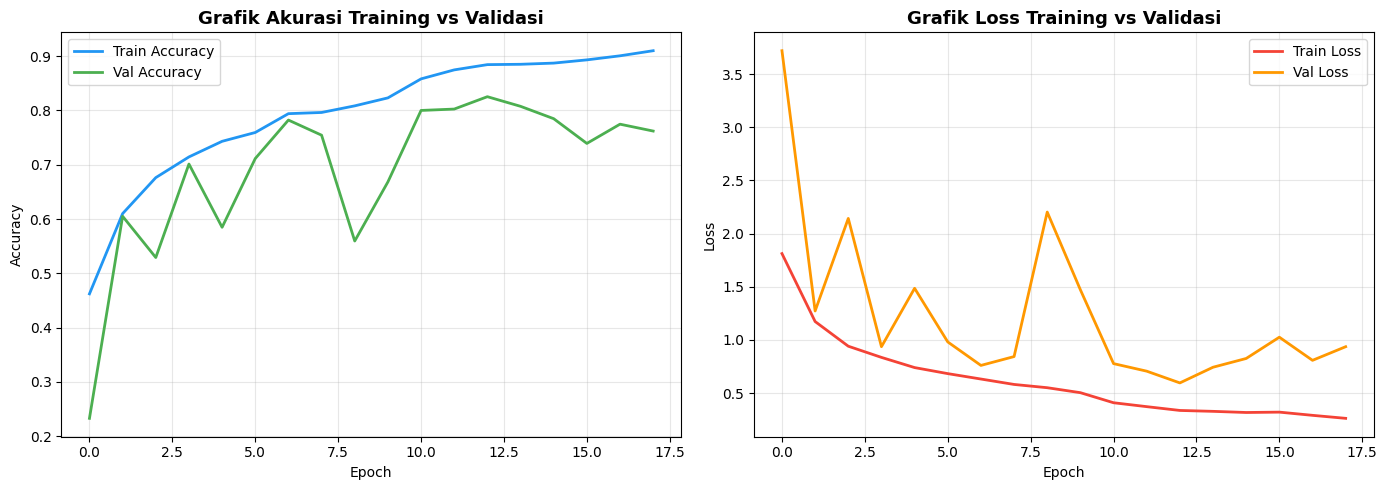

13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step


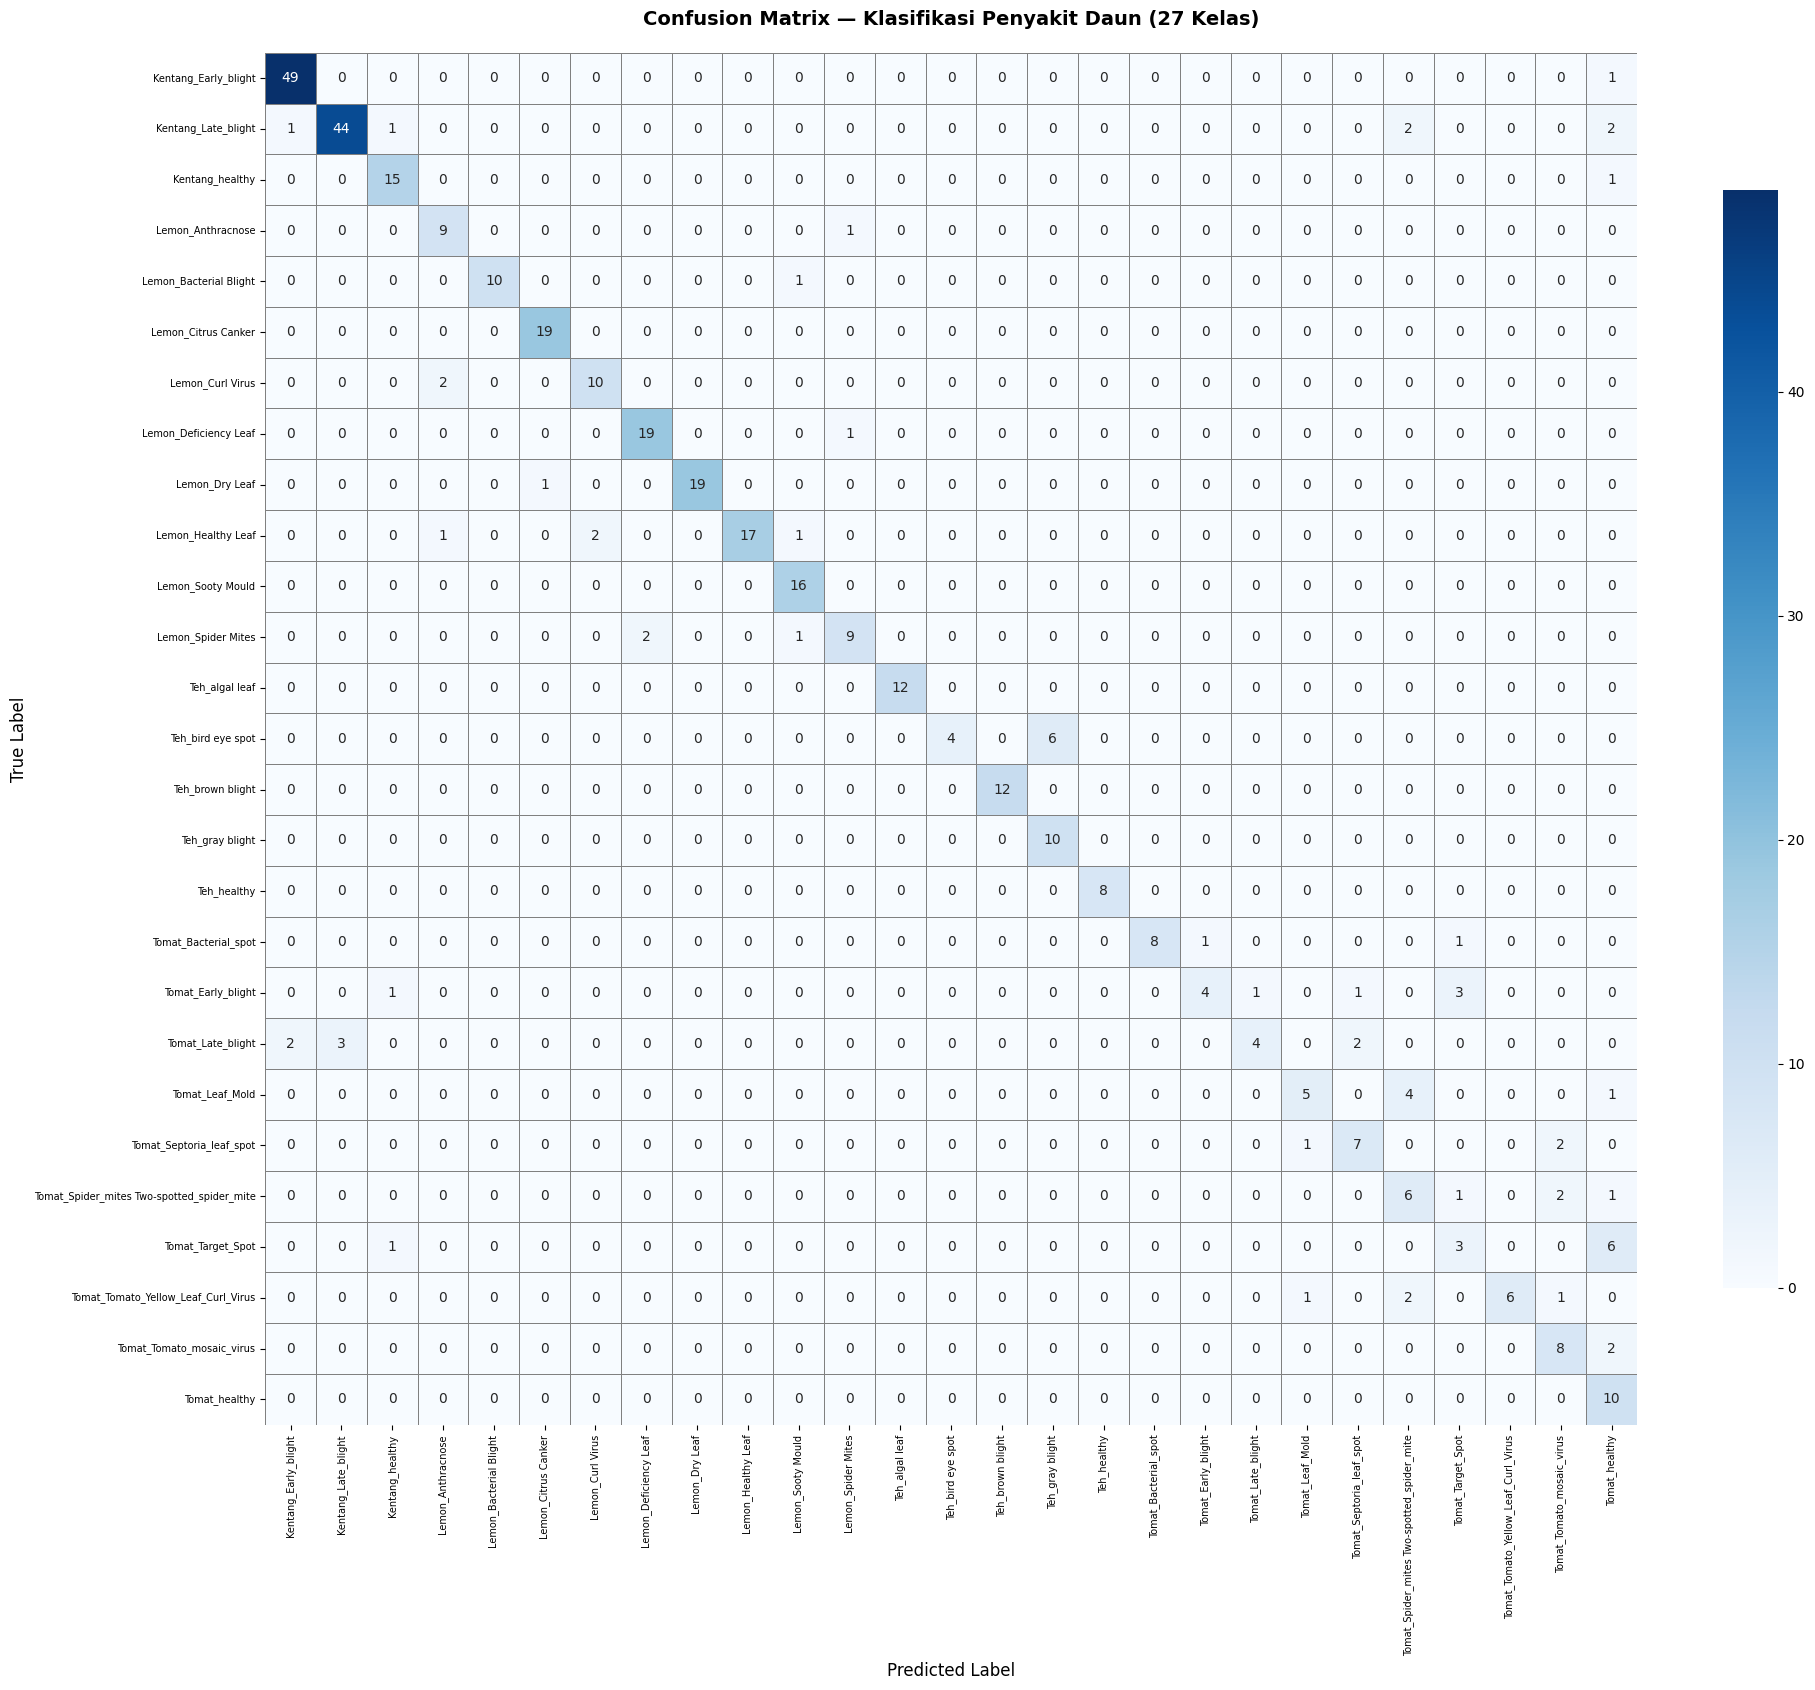


 Diagonal = prediksi benar | Off-diagonal = salah klasifikasi

CLASSIFICATION REPORT
                                            precision    recall  f1-score   support

                      Kentang_Early_blight       0.94      0.98      0.96        50
                       Kentang_Late_blight       0.94      0.88      0.91        50
                           Kentang_healthy       0.83      0.94      0.88        16
                         Lemon_Anthracnose       0.75      0.90      0.82        10
                    Lemon_Bacterial Blight       1.00      0.91      0.95        11
                       Lemon_Citrus Canker       0.95      1.00      0.97        19
                          Lemon_Curl Virus       0.83      0.83      0.83        12
                     Lemon_Deficiency Leaf       0.90      0.95      0.93        20
                            Lemon_Dry Leaf       1.00      0.95      0.97        20
                        Lemon_Healthy Leaf       1.00      0.81      0.89

In [ ]:
# ============================================================
# CELL 9 — Evaluasi Model
# Menampilkan:
#   1. Akurasi pada data test
#   2. Grafik akurasi & loss (train vs val)
#   3. Confusion Matrix (Heatmap) untuk 27 kelas
#   4. Classification Report
#
# Alasan menggunakan Heatmap untuk Confusion Matrix:
# Dengan 27 kelas, confusion matrix teks sangat panjang dan sulit dibaca. Heatmap memudahkan untuk melihat secara visual penyakit mana yang sering tertukar oleh model
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Evaluasi pada Data Test
print("=" * 60)
print("EVALUASI MODEL PADA DATA TEST")
print("=" * 60)

test_loss, test_acc = model.evaluate(test_generator, verbose=1)
print(f"\n Test Loss   : {test_loss:.4f}")
print(f" Test Accuracy : {test_acc * 100:.2f}%")

# 2. Grafik Akurasi & Loss (Train vs Validation)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Akurasi
axes[0].plot(history.history['accuracy'],     label='Train Accuracy',  color='#2196F3', linewidth=2)
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy',    color='#4CAF50', linewidth=2)
axes[0].set_title('Grafik Akurasi Training vs Validasi', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(history.history['loss'],     label='Train Loss',  color='#F44336', linewidth=2)
axes[1].plot(history.history['val_loss'], label='Val Loss',    color='#FF9800', linewidth=2)
axes[1].set_title('Grafik Loss Training vs Validasi', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("training_history.png", dpi=150, bbox_inches='tight')
plt.show()

# 3. Prediksi & Label Asli

# Reset generator agar prediksi mulai dari awal (penting: shuffle=False)
test_generator.reset()

y_pred_probs = model.predict(test_generator, verbose=1)
y_pred       = np.argmax(y_pred_probs, axis=1)   # Kelas prediksi
y_true       = test_generator.classes            # Label asli

# Nama kelas dari generator
class_labels = list(test_generator.class_indices.keys())

# 4. Confusion Matrix Heatmap
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(20, 17))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels,
    linewidths=0.5,
    linecolor='gray',
    cbar_kws={'shrink': 0.8}
)

plt.title('Confusion Matrix — Klasifikasi Penyakit Daun (27 Kelas)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label',      fontsize=12)
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0,  fontsize=7)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches='tight')
plt.show()

print("\n Diagonal = prediksi benar | Off-diagonal = salah klasifikasi")

# 5. Classification Report
print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_true, y_pred, target_names=class_labels))

In [ ]:
# ============================================================
# CELL 10 — Backup Split Dataset ke Google Drive
#
# PERHATIAN: SELURUH BARIS KODE DI BAWAH INI DINONAKTIFKAN (di-comment) agar TIDAK otomatis tereksekusi.
#
# Fungsi cell ini:
#   → Mengompres folder split hasil Cell 5 menjadi file .zip
#   → Menyalin file .zip tersebut ke Google Drive sebagai backup
#
# Cara menggunakan (jika diperlukan):
#   1. Hapus tanda '#' di depan setiap baris kode di bawah
#   2. Jalankan cell ini SETELAH Cell 5 selesai
#   3. Pastikan Google Drive sudah ter-mount (Cell 2)
#
# Catatan: Proses ini membutuhkan waktu cukup lama tergantung ukuran dataset. Hanya perlu dijalankan satu kali untuk backup.
# ============================================================

# import os
# import shutil

# # Path sumber folder split di lokal Colab
# SPLIT_PATH = "/content/dataset/split"

# # Nama file backup
# BACKUP_NAME = "split_dataset_backup"

# # Path tujuan backup di Google Drive
# DRIVE_BACKUP_PATH = "/content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/dataset/split"

# print("Mengompres folder split menjadi .zip ...")
# # Kompres folder split menjadi .zip di direktori /content
# shutil.make_archive(
#     base_name=f"/content/{BACKUP_NAME}",  # Nama output (tanpa ekstensi)
#     format='zip',                          # Format: zip
#     root_dir="/content/dataset",           # Root dari path yang dikompres
#     base_dir="split"                       # Folder yang dikompres
# )
# print(f"Kompresi selesai: /content/{BACKUP_NAME}.zip")

# # Buat folder tujuan di Drive jika belum ada
# os.makedirs(DRIVE_BACKUP_PATH, exist_ok=True)

# # Salin file .zip ke Google Drive
# print(f"\n Menyalin ke Google Drive: {DRIVE_BACKUP_PATH} ...")
# shutil.copy(
#     f"/content/{BACKUP_NAME}.zip",
#     f"{DRIVE_BACKUP_PATH}/{BACKUP_NAME}.zip"
# )
# print(f"Backup berhasil disimpan ke Drive!")
# print(f"Path : {DRIVE_BACKUP_PATH}/{BACKUP_NAME}.zip")

In [ ]:
# ============================================================
# CELL 11 — Menyimpan Model Final & Download
#
# Cell ini menyimpan bobot final model yang sudah dilatih dan menyiapkan file label (kamus kelas) untuk keperluan inferensi/deployment di luar Colab.
#
# Dua file yang dihasilkan:
#   1. model_final_ifest.h5  → Bobot model CNN final
#   2. class_indices.json    → Kamus label (index → nama kelas)
#
# Catatan untuk juri:
# Aktifkan baris files.download() di bawah jika ingin mengunduh file model dan label secara otomatis ke perangkat lokal.
# ============================================================

import json
from google.colab import files

# Menyimpan Model Final
MODEL_FINAL_PATH = "model_final_ifest.h5"
model.save(MODEL_FINAL_PATH)
print(f"Model final berhasil disimpan: {MODEL_FINAL_PATH}")

# Simpan Kamus Label (class_indices.json)
# Membuat kamus dari class_indices generator dengan {nama_kelas: index}
# Membalik kamus agar format menjadi {index: nama_kelas} untuk kemudahan inferensi
class_indices = train_generator.class_indices
index_to_class = {str(v): k for k, v in class_indices.items()}

# Menyimpan ke file JSON menggunakan library json
with open("class_indices.json", "w") as f:
    json.dump(index_to_class, f, indent=4)

print(f"Kamus label berhasil disimpan: class_indices.json")
print(f"Total kelas: {len(index_to_class)} kelas")

# Preview isi kamus
print("\n Preview class_indices.json:")
for idx, cls in sorted(index_to_class.items(), key=lambda x: int(x[0])):
    print(f"   [{idx:>2}] → {cls}")

# Download File
# Aktifkan baris di bawah ini jika ingin mengunduh file model dan label secara otomatis ke perangkat lokal.
# files.download('model_final_ifest.h5')
# files.download('class_indices.json')

Model final berhasil disimpan: model_final_ifest.h5
Kamus label berhasil disimpan: class_indices.json
Total kelas: 27 kelas

 Preview class_indices.json:
   [ 0] → Kentang_Early_blight
   [ 1] → Kentang_Late_blight
   [ 2] → Kentang_healthy
   [ 3] → Lemon_Anthracnose
   [ 4] → Lemon_Bacterial Blight
   [ 5] → Lemon_Citrus Canker
   [ 6] → Lemon_Curl Virus
   [ 7] → Lemon_Deficiency Leaf
   [ 8] → Lemon_Dry Leaf
   [ 9] → Lemon_Healthy Leaf
   [10] → Lemon_Sooty Mould
   [11] → Lemon_Spider Mites
   [12] → Teh_algal leaf
   [13] → Teh_bird eye spot
   [14] → Teh_brown blight
   [15] → Teh_gray blight
   [16] → Teh_healthy
   [17] → Tomat_Bacterial_spot
   [18] → Tomat_Early_blight
   [19] → Tomat_Late_blight
   [20] → Tomat_Leaf_Mold
   [21] → Tomat_Septoria_leaf_spot
   [22] → Tomat_Spider_mites Two-spotted_spider_mite
   [23] → Tomat_Target_Spot
   [24] → Tomat_Tomato_Yellow_Leaf_Curl_Virus
   [25] → Tomat_Tomato_mosaic_virus
   [26] → Tomat_healthy


##Hasil Analisis dan Kesimpulan
Berdasarkan hasil pengujian pada data test, model CNN yang kami kembangkan berhasil mencapai akurasi sebesar 83,66% dengan rata-rata F1-score 0,79. Kami mengamati bahwa model memiliki performa yang sangat stabil pada komoditas Teh dan Lemon, bahkan mencapai skor sempurna (1.00) pada beberapa kelas seperti Teh_algal_leaf dan Lemon_Bacterial_Blight. Hal ini membuktikan bahwa arsitektur CNN yang kami rancang sangat efektif dalam mengekstraksi fitur morfologi daun yang memiliki kontras visual serta karakteristik tekstur yang unik.

Namun, kami mengidentifikasi tantangan klasifikasi pada keluarga Solanaceae, khususnya pada tanaman Tomat yang memiliki rentang skor F1 antara 0,33 hingga 0,89. Melalui analisis confusion matrix, ditemukan adanya misklasifikasi antar penyakit dalam jenis tanaman yang sama, seperti Tomat_Early_blight yang sering tertukar dengan Tomat_Target_Spot. Hal ini secara ilmiah sangat wajar terjadi karena kemiripan pola visual gejala penyakit (symptom overlap) pada genus Solanum. Penyakit-penyakit tersebut sering kali menunjukkan karakteristik bercak cokelat konsentris yang hampir identik, sehingga sulit dibedakan hanya melalui fitur visual kasar tanpa bantuan detail mikroskopis.

Sebagai kesimpulan, angka akurasi 83,66% dalam mengklasifikasikan 27 kelas penyakit merupakan pencapaian yang baik mengingat tingginya kompleksitas data dan adanya kemiripan genetik antar spesies. Model kami telah menunjukkan kemampuan generalisasi yang baik dan tidak mengalami overfitting.